# Кластеризация клиентов Т-Банка (KMeans)

**Цель:** выделить поведенческие сегменты клиентов на основе их транзакционной активности. Используем KMeans — классический метод кластеризации. Признаки: частота, сумма трат, средний чек, разнообразие категорий, доля трат в выходные и в самой популярной категории.

**Данные:** `data/processed/transactions_clean.csv` (14,0 млн транзакций, 50 000 клиентов), `data/processed/rfm_segments.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Настройки визуализации
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Пути
DATA_PATH = Path('../data/processed/transactions_clean.csv')
RFM_PATH = Path('../data/processed/rfm_segments.csv')
IMAGES_CLUST = Path('../images/clustering')

# Загрузка
df = pd.read_csv(DATA_PATH, parse_dates=['transaction_dttm'])
rfm = pd.read_csv(RFM_PATH)

print(f"Транзакции: {df.shape[0]:,} строк")
print(f"RFM-таблица: {rfm.shape[0]:,} клиентов")

Транзакции: 14,036,337 строк
RFM-таблица: 50,000 клиентов


## 1. Создание поведенческих признаков

Агрегируем транзакции на уровне клиента и добавляем метрики, которые характеризуют стиль потребления.

In [2]:
# Основные агрегаты
agg = df.groupby('party_rk').agg(
    freq=('transaction_amt', 'count'),
    monetary=('transaction_amt', 'sum'),
    n_categories=('category', 'nunique'),
    n_merchants=('merchant_group_rk', 'nunique'),
    weekend_share=('is_weekend', 'mean')
).reset_index()

# Средний чек
agg['avg_check'] = agg['monetary'] / agg['freq']

# Доля трат в самой популярной категории клиента
top_category = df.groupby(['party_rk', 'category'])['transaction_amt'].sum().reset_index()
top_category = top_category.sort_values(['party_rk', 'transaction_amt'], ascending=[True, False])
top_category = top_category.groupby('party_rk').head(1)[['party_rk', 'transaction_amt']]
top_category.columns = ['party_rk', 'top_category_amount']

agg = agg.merge(top_category, on='party_rk', how='left')
agg['top_category_share'] = agg['top_category_amount'] / agg['monetary']
agg = agg.drop(columns=['top_category_amount'])

print(f"Признаки на уровне клиента: {agg.shape}")
agg.head()

Признаки на уровне клиента: (50000, 8)


,party_rk,freq,monetary,n_categories,n_merchants,weekend_share,avg_check,top_category_share
0,1,828,3181737.0,24,49,0.245169,3842.677536,0.704317
1,2,539,250979.0,11,18,0.168831,465.638219,0.501233
2,3,919,4637115.0,26,57,0.214363,5045.826986,0.454973
3,4,999,2276923.0,31,80,0.219219,2279.202202,0.447191
4,5,638,1575196.0,22,38,0.205329,2468.959248,0.560558


In [3]:
# Присоединяем RFM
features = agg.merge(rfm[['party_rk', 'recency']], on='party_rk', how='inner')

print(f"Итоговая таблица: {features.shape}")
features.describe()

Итоговая таблица: (50000, 9)


,party_rk,freq,monetary,n_categories,n_merchants,weekend_share,avg_check,top_category_share,recency
count,50000.000000,50000.000000,5.000000e+04,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,280.726740,7.723733e+05,14.76162,23.43644,0.212973,3087.268011,0.526777,29.512080
std,14433.901067,272.596614,1.199225e+06,6.70649,19.40298,0.064259,4709.732565,0.144686,64.665486
min,1.000000,13.000000,1.886000e+03,1.00000,1.00000,0.000000,28.394737,0.157437,1.000000
25%,12500.750000,79.000000,1.352718e+05,10.00000,9.00000,0.172624,1046.182415,0.426606,1.000000
50%,25000.500000,169.000000,3.270575e+05,14.00000,17.00000,0.208333,1846.715051,0.509938,4.000000
75%,37500.250000,395.000000,9.139428e+05,19.00000,32.00000,0.249188,3368.267403,0.612389,19.000000
max,50000.000000,1498.000000,2.784728e+07,36.00000,144.00000,0.666667,129236.137931,1.000000,420.000000


## 2. Подготовка признаков

Признаки имеют разные масштабы и сильную асимметрию. Логарифмируем денежные и счётные метрики, затем стандартизируем.

In [4]:
# Выбираем признаки для кластеризации
feature_cols = ['freq', 'monetary', 'avg_check', 'n_categories',
                'n_merchants', 'weekend_share', 'top_category_share', 'recency']

X = features[feature_cols].copy()

# Логарифмируем денежные и счётные признаки (recency тоже скошен)
log_cols = ['freq', 'monetary', 'avg_check', 'n_categories', 'n_merchants', 'recency']
for col in log_cols:
    X[col] = np.log1p(X[col])

# Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Матрица признаков: {X_scaled.shape}")
print(f"Среднее после стандартизации: {X_scaled.mean(axis=0).round(2)}")
print(f"Стд после стандартизации: {X_scaled.std(axis=0).round(2)}")

Матрица признаков: (50000, 8)
Среднее после стандартизации: [ 0.  0. -0. -0.  0. -0.  0.  0.]
Стд после стандартизации: [1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Выбор оптимального числа кластеров

Используем два подхода:
- **Метод Elbow:** смотрим на внутрикластерную сумму квадратов.
- **Silhouette score:** оцениваем качество разделения (чем выше, тем лучше).

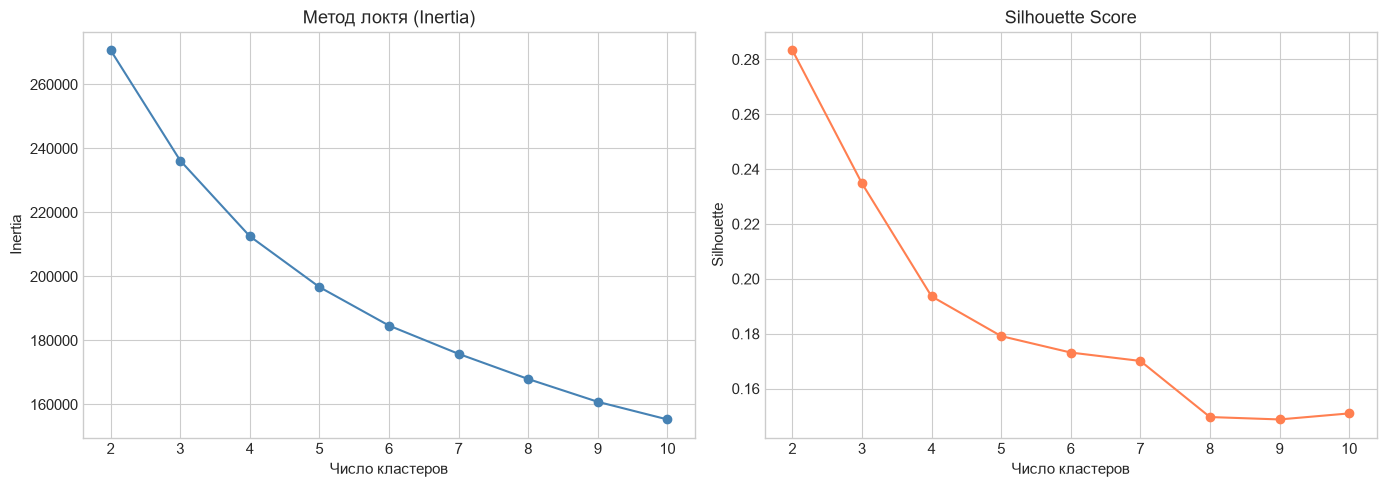

Оптимальное число кластеров по silhouette: 2


In [5]:
inertia = []
silhouette = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels, sample_size=10000, random_state=42))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia, marker='o', color='steelblue')
axes[0].set_title('Метод локтя (Inertia)')
axes[0].set_xlabel('Число кластеров')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, silhouette, marker='o', color='coral')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Число кластеров')
axes[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.savefig(IMAGES_CLUST / '01_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

# Лучший k по silhouette
best_k = k_range[np.argmax(silhouette)]
print(f"Оптимальное число кластеров по silhouette: {best_k}")

**Вывод:** оптимальное число кластеров по silhouette score — **k = 2**. Silhouette-максимум приходится на минимально возможное значение из проверенного диапазона (2–10), что говорит о выраженной бинарной структуре поведенческих признаков.

## 4. Кластеризация KMeans

Обучаем модель с выбранным числом кластеров и добавляем метки в таблицу.

In [6]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
features['cluster'] = kmeans.fit_predict(X_scaled)

cluster_counts = features['cluster'].value_counts().sort_index()
print(f"Распределение по кластерам:\n{cluster_counts}")

Распределение по кластерам:
cluster
0    25999
1    24001
Name: count, dtype: int64


## 5. Профилирование кластеров

Смотрим на средние значения признаков в каждом кластере, чтобы дать им осмысленные названия.

In [7]:
profile = features.groupby('cluster')[feature_cols].mean().round(2)
profile['n_clients'] = cluster_counts
print(profile)

           freq    monetary  avg_check  n_categories  n_merchants  \
cluster                                                             
0        101.82   225366.90    2904.72          9.82        10.54   
1        474.53  1364916.13    3285.02         20.11        37.40   

         weekend_share  top_category_share  recency  n_clients  
cluster                                                         
0                 0.22                0.54    50.52      25999  
1                 0.21                0.51     6.75      24001  


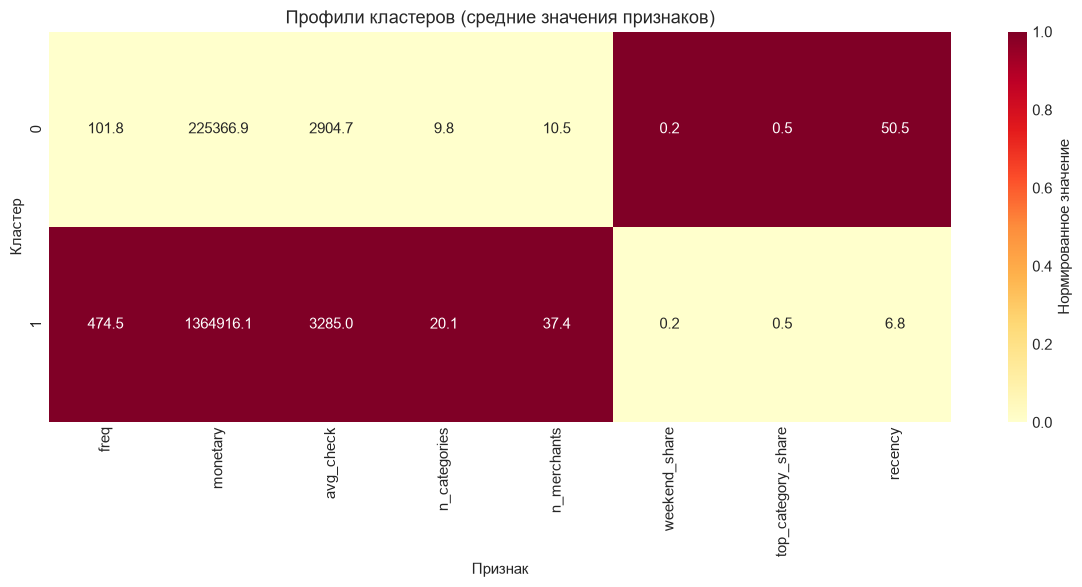

In [8]:
# Нормируем признаки для heatmap (чтобы цвета были сопоставимы)
denom = profile[feature_cols].max() - profile[feature_cols].min()
denom = denom.replace(0, 1)
profile_norm = (profile[feature_cols] - profile[feature_cols].min()) / denom

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(profile_norm, annot=profile[feature_cols], fmt='.1f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Нормированное значение'})
ax.set_title('Профили кластеров (средние значения признаков)')
ax.set_xlabel('Признак')
ax.set_ylabel('Кластер')
plt.tight_layout()
plt.savefig(IMAGES_CLUST / '02_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** кластеры различаются по признакам активности. Кластер 0 (25 999 клиентов) — низкая активность: давность последней покупки 50,5 дня, ~102 транзакции на клиента, 10 категорий, 11 мерчантов. Кластер 1 (24 001 клиент) — высокая активность: давность 6,75 дня, ~475 транзакций на клиента, 20 категорий, 37 мерчантов. Доля трат в выходные (0,22 vs 0,21) и доля в самой популярной категории (0,54 vs 0,51) почти совпадают — эти признаки кластеры не разделяют.

## 6. Визуализация кластеров (PCA)

Снижаем размерность до 2 компонентов для наглядной визуализации разделения.

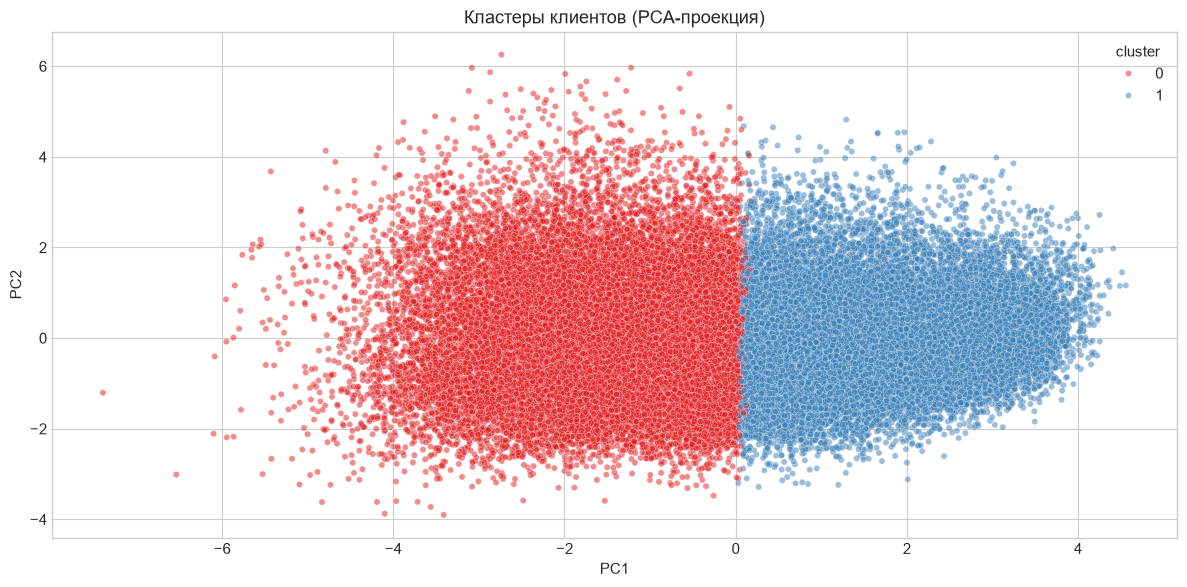

In [9]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

features['pca1'] = X_pca[:, 0]
features['pca2'] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=features, x='pca1', y='pca2', hue='cluster', palette='Set1', alpha=0.5, ax=ax, s=20)
ax.set_title('Кластеры клиентов (PCA-проекция)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.tight_layout()
plt.savefig(IMAGES_CLUST / '03_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** на PCA-проекции кластеры образуют два частично перекрывающихся облака. Разделение идёт преимущественно вдоль первой главной компоненты (PC1), что согласуется с различиями в частоте и сумме трат.

## 7. Сохранение результатов

Сохраняем таблицу с метками кластеров для дальнейшей загрузки в PostgreSQL и построения дашборда.

In [10]:
result_path = Path('../data/processed/clusters.csv')
features.to_csv(result_path, index=False)
print(f"Результаты кластеризации сохранены в {result_path}")

Результаты кластеризации сохранены в ..\data\processed\clusters.csv


## 8. Выводы

- **Оптимальное число кластеров:** 2 (по максимальному silhouette score).
- **Профили кластеров:** кластер 0 — низкая активность (давность 50,5 дня, ~102 транзакции, 10 категорий), кластер 1 — высокая активность (давность 6,75 дня, ~475 транзакций, 20 категорий). Доли трат в выходные и в популярной категории в обоих кластерах почти одинаковы.
- **PCA-визуализация:** кластеры образуют два облака с частичным пересечением, разделение идёт вдоль PC1.
- **Сохранение:** 50 000 строк с метками кластеров и PCA-координатами записаны в `data/processed/clusters.csv`.